In [45]:
# ---------------------------------------------------
# 1. IMPORT LIBRARIES
# ---------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
 

In [46]:

# ---------------------------------------------------
# 2. LOAD DATASET
# ---------------------------------------------------
df = pd.read_csv("5-sales_data_sample.csv", encoding="latin1")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue

In [47]:

# ---------------------------------------------------
# 3. SELECT FEATURES AND HANDLE MISSING VALUES
# ---------------------------------------------------
features = ["SALES", "QUANTITYORDERED", "PRICEEACH", "MSRP"]

df = df.dropna(subset=features)
X = df[features]

print("Shape after removing missing values:", X.shape)


Shape after removing missing values: (2823, 4)


In [48]:

# ---------------------------------------------------
# 4. FEATURE SCALING
# ---------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

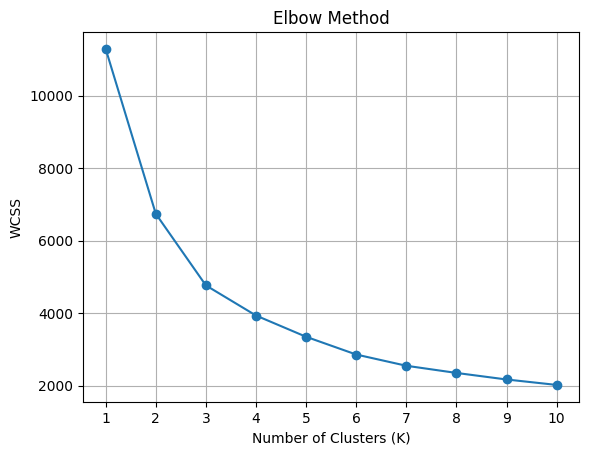

In [49]:

# ---------------------------------------------------
# 5. ELBOW METHOD (TO FIND NUMBER OF CLUSTERS)
# ---------------------------------------------------
wcss = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

# plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss,marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [50]:

# ---------------------------------------------------
# 6. CHOOSE K FROM THE ELBOW GRAPH
# (look at the graph above and put the K where the curve bends)
# ---------------------------------------------------
optimal_k = 3

# ---------------------------------------------------
# 7. K-MEANS CLUSTERING
# ---------------------------------------------------
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts())


K-Means Cluster Counts:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


In [51]:

# ---------------------------------------------------
# 8. HIERARCHICAL CLUSTERING
# ---------------------------------------------------
hc = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
df["Hierarchical_Cluster"] = hc.fit_predict(X_scaled)

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts())


Hierarchical Cluster Counts:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


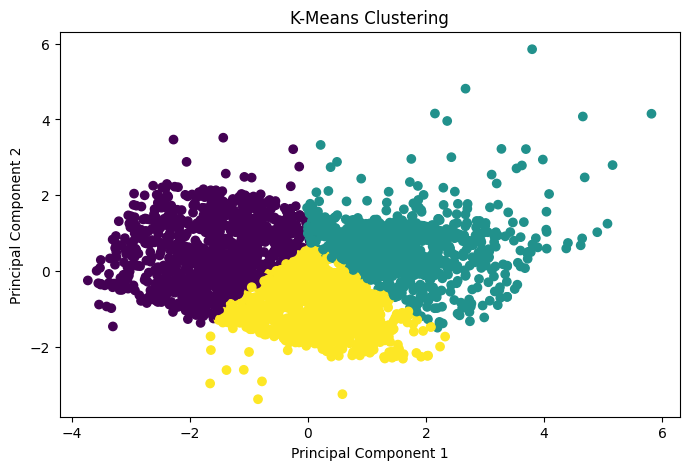

In [56]:

# ---------------------------------------------------
# 9. VISUALISATION
# ---------------------------------------------------
# Reduce data to 2 dimensions so it can be plotted
X_pca = PCA(n_components=2).fit_transform(X_scaled)

# K-Means plot
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["KMeans_Cluster"])
plt.title("K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

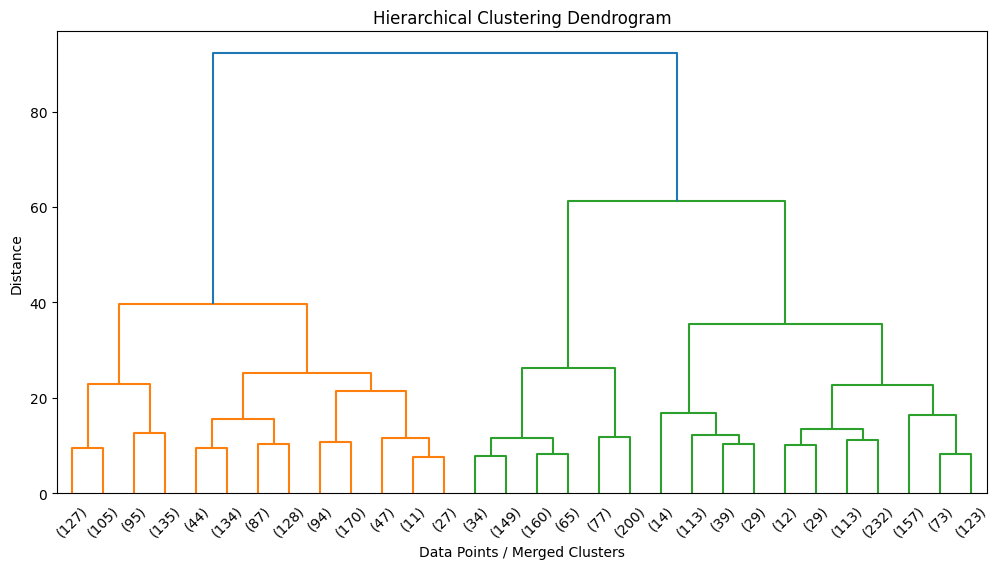

In [53]:

# # Dendrogram
# plt.figure(figsize=(12, 6))
# Z = linkage(X_scaled, method="ward")
# dendrogram(Z, truncate_mode="lastp", p=30)
# plt.title("Hierarchical Clustering Dendrogram")
# plt.xlabel("Data Points / Merged Clusters")
# plt.ylabel("Distance")
# plt.show()

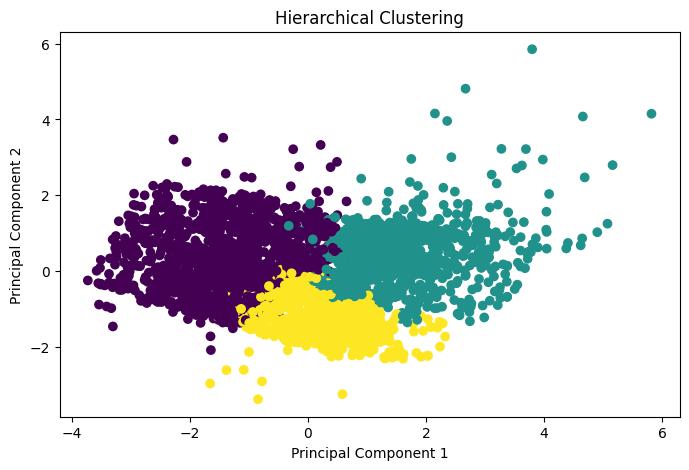

In [57]:

# Hierarchical plot
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["Hierarchical_Cluster"])
plt.title("Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [55]:

# ---------------------------------------------------
# 10. CLUSTER ANALYSIS (average values of each cluster)
# ---------------------------------------------------
print("\nK-Means Cluster Analysis:")
print(df.groupby("KMeans_Cluster")[features].mean())

print("\nHierarchical Cluster Analysis:")
print(df.groupby("Hierarchical_Cluster")[features].mean())


K-Means Cluster Analysis:
                      SALES  QUANTITYORDERED  PRICEEACH        MSRP
KMeans_Cluster                                                     
0               2101.076482        35.208205  59.551169   64.145641
1               5720.080669        43.723005  97.479261  127.893192
2               3123.062801        27.597390  95.435090  113.266064

Hierarchical Cluster Analysis:
                            SALES  QUANTITYORDERED  PRICEEACH        MSRP
Hierarchical_Cluster                                                     
0                     2273.005623        35.479236  63.746694   70.546512
1                     5575.633972        41.710921  99.286777  127.048180
2                     3048.595547        25.389781  97.347737  117.837956
